# BIM 430 - Derin Öğrenme Proje Ödevi
## Drone vs Bird Sınıflandırma - Özel CNN Modeli

**Veri Seti:** [Drone vs Bird](https://www.kaggle.com/datasets/muhammadsaoodsarwar/drone-vs-bird)

**Sınıflar (2):** Bird, Drone

**Amaç:** Hava görüntülerinde drone ve kuş ayrımı yapabilen sıfırdan tasarlanmış bir CNN modeli geliştirmek.

## 1. Kurulum ve Veri Seti İndirme

In [1]:
!pip install -q kagglehub

In [2]:
import kagglehub

path = kagglehub.dataset_download("muhammadsaoodsarwar/drone-vs-bird")
print("Veri seti yolu:", path)

Using Colab cache for faster access to the 'drone-vs-bird' dataset.
Veri seti yolu: /kaggle/input/drone-vs-bird


In [3]:
import os

print("İndirilen dosyalar:")
for item in sorted(os.listdir(path)):
    print(f"  {item}")
    sub_path = os.path.join(path, item)
    if os.path.isdir(sub_path):
        for sub_item in sorted(os.listdir(sub_path)):
            sub_sub = os.path.join(sub_path, sub_item)
            if os.path.isdir(sub_sub):
                count = len(os.listdir(sub_sub))
                print(f"    {sub_item}/ ({count} dosya)")
            else:
                print(f"    {sub_item}")

İndirilen dosyalar:
  dataset
    bird/ (1607 dosya)
    drone/ (2499 dosya)


## 2. Kütüphanelerin İçe Aktarılması

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
import shutil

print(f"TensorFlow sürümü: {tf.__version__}")
print(f"GPU kullanılabilir: {tf.config.list_physical_devices('GPU')}")

TensorFlow sürümü: 2.19.0
GPU kullanılabilir: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Veri Setinin Hazırlanması

Veri seti sadece `bird/` ve `drone/` klasörlerinden oluşuyor. Eğitim, doğrulama ve test setlerine bölmemiz gerekiyor.

In [5]:
DATASET_DIR = os.path.join(path, 'dataset')

if not os.path.isdir(DATASET_DIR):
    candidates = [d for d in os.listdir(path) if os.path.isdir(os.path.join(path, d))]
    if len(candidates) == 2:
        DATASET_DIR = path
    elif len(candidates) == 1:
        DATASET_DIR = os.path.join(path, candidates[0])

class_names = sorted([d for d in os.listdir(DATASET_DIR) if os.path.isdir(os.path.join(DATASET_DIR, d))])
print(f"Sınıflar: {class_names}")
for cls in class_names:
    cls_path = os.path.join(DATASET_DIR, cls)
    count = len([f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg','.jpeg','.png','.bmp','.webp'))])
    print(f"  {cls}: {count} görüntü")

Sınıflar: ['bird', 'drone']
  bird: 1607 görüntü
  drone: 2499 görüntü


In [6]:
SPLIT_DIR = './split_data'

if os.path.exists(SPLIT_DIR):
    shutil.rmtree(SPLIT_DIR)

for split in ['train', 'val', 'test']:
    for cls in class_names:
        os.makedirs(os.path.join(SPLIT_DIR, split, cls), exist_ok=True)

for cls in class_names:
    cls_path = os.path.join(DATASET_DIR, cls)
    all_files = [f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg','.jpeg','.png','.bmp','.webp'))]

    train_files, test_files = train_test_split(all_files, test_size=0.2, random_state=42)
    train_files, val_files = train_test_split(train_files, test_size=0.15, random_state=42)

    for f in train_files:
        shutil.copy2(os.path.join(cls_path, f), os.path.join(SPLIT_DIR, 'train', cls, f))
    for f in val_files:
        shutil.copy2(os.path.join(cls_path, f), os.path.join(SPLIT_DIR, 'val', cls, f))
    for f in test_files:
        shutil.copy2(os.path.join(cls_path, f), os.path.join(SPLIT_DIR, 'test', cls, f))

    print(f"{cls}: train={len(train_files)}, val={len(val_files)}, test={len(test_files)}")

TRAIN_DIR = os.path.join(SPLIT_DIR, 'train')
VAL_DIR = os.path.join(SPLIT_DIR, 'val')
TEST_DIR = os.path.join(SPLIT_DIR, 'test')

bird: train=1092, val=193, test=322
drone: train=1699, val=300, test=500


## 4. Veri Yükleme ve Ön İşleme

In [7]:
IMG_SIZE = 128
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1.0/255.0,
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_test_datagen = ImageDataGenerator(rescale=1.0/255.0)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True
)

val_generator = val_test_datagen.flow_from_directory(
    VAL_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

test_generator = val_test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

class_names = list(train_generator.class_indices.keys())
num_classes = len(class_names)
print(f"\nSınıf isimleri: {class_names}")
print(f"Sınıf indeksleri: {train_generator.class_indices}")
print(f"Eğitim seti: {train_generator.samples} görüntü")
print(f"Doğrulama seti: {val_generator.samples} görüntü")
print(f"Test seti: {test_generator.samples} görüntü")

Found 2789 images belonging to 2 classes.
Found 493 images belonging to 2 classes.
Found 822 images belonging to 2 classes.

Sınıf isimleri: ['bird', 'drone']
Sınıf indeksleri: {'bird': 0, 'drone': 1}
Eğitim seti: 2789 görüntü
Doğrulama seti: 493 görüntü
Test seti: 822 görüntü


## 5. Veri Keşfi ve Görselleştirme

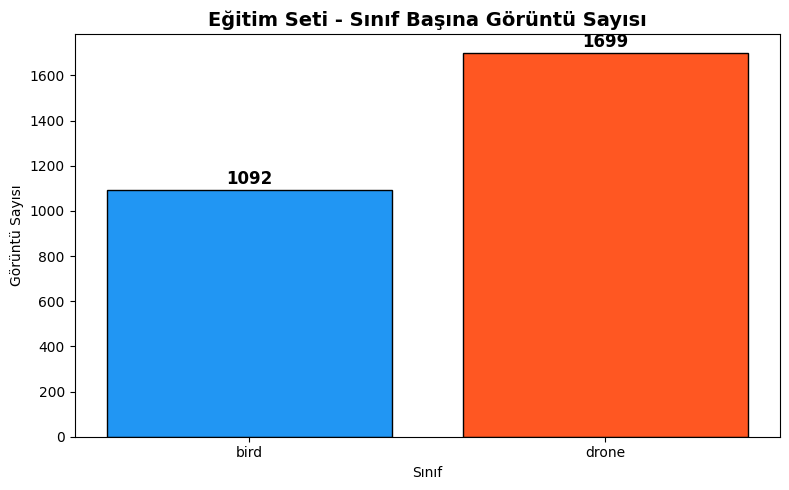

In [8]:
train_counts = {}
for cls in class_names:
    train_counts[cls] = len(os.listdir(os.path.join(TRAIN_DIR, cls)))

plt.figure(figsize=(8, 5))
colors = ['#2196F3', '#FF5722']
bars = plt.bar(train_counts.keys(), train_counts.values(), color=colors, edgecolor='black')
plt.title('Eğitim Seti - Sınıf Başına Görüntü Sayısı', fontsize=14, fontweight='bold')
plt.xlabel('Sınıf')
plt.ylabel('Görüntü Sayısı')
for bar, count in zip(bars, train_counts.values()):
    plt.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 10,
             str(count), ha='center', va='bottom', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

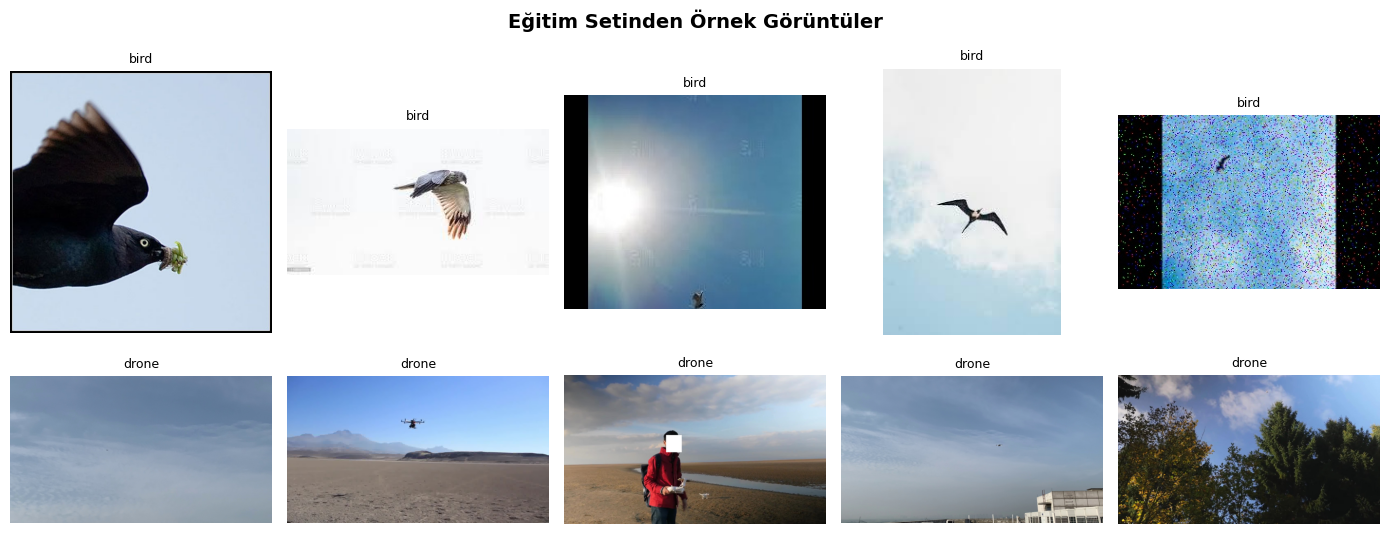

In [9]:
plt.figure(figsize=(14, 6))
for idx, cls in enumerate(class_names):
    cls_path = os.path.join(TRAIN_DIR, cls)
    files = os.listdir(cls_path)[:5]
    for i, f in enumerate(files):
        plt.subplot(2, 5, idx*5 + i + 1)
        img = plt.imread(os.path.join(cls_path, f))
        plt.imshow(img)
        if i == 0:
            plt.ylabel(cls.upper(), fontsize=12, fontweight='bold')
        plt.title(cls, fontsize=9)
        plt.axis('off')
plt.suptitle('Eğitim Setinden Örnek Görüntüler', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Özel CNN Model Mimarisi

Tamamen sıfırdan tasarlanmış özel bir CNN mimarisi.

**Mimari Özellikleri:**
- 4 adet Konvolüsyon Bloğu (Conv2D → BatchNorm → ReLU → Conv2D → BatchNorm → ReLU → MaxPool → Dropout)
- Artan filtre sayıları: 32 → 64 → 128 → 256
- Global Average Pooling ile düzleştirme
- Tam Bağlantılı (Dense) katmanlar ile sınıflandırma
- Batch Normalization ile eğitimi stabilize etme
- Dropout ile aşırı öğrenmeyi (overfitting) önleme
- İkili sınıflandırma için sigmoid çıkış katmanı

In [10]:
def build_custom_cnn(input_shape=(128, 128, 3)):
    inputs = layers.Input(shape=input_shape)

    # --- Blok 1: 32 filtre ---
    x = layers.Conv2D(32, (3, 3), padding='same')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(32, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(pool_size=(2, 2))(x)
    x = layers.Dropout(0.25)(x)

    # --- Blok 2: 64 filtre ---
    x = layers.Conv2D(64, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(64, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(pool_size=(2, 2))(x)
    x = layers.Dropout(0.25)(x)

    # --- Blok 3: 128 filtre ---
    x = layers.Conv2D(128, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(128, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(pool_size=(2, 2))(x)
    x = layers.Dropout(0.3)(x)

    # --- Blok 4: 256 filtre ---
    x = layers.Conv2D(256, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(256, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(pool_size=(2, 2))(x)
    x = layers.Dropout(0.3)(x)

    # --- Sınıflandırma Katmanları ---
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(128)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = Model(inputs=inputs, outputs=outputs, name='Custom_DroneVsBird_CNN')
    return model

model = build_custom_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3))
model.summary()

Model: "Custom_DroneVsBird_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,276,449 (4.87 MB)

 Trainable params: 1,273,761 (4.86 MB)

 Non-trainable params: 2,688 (10.50 KB)

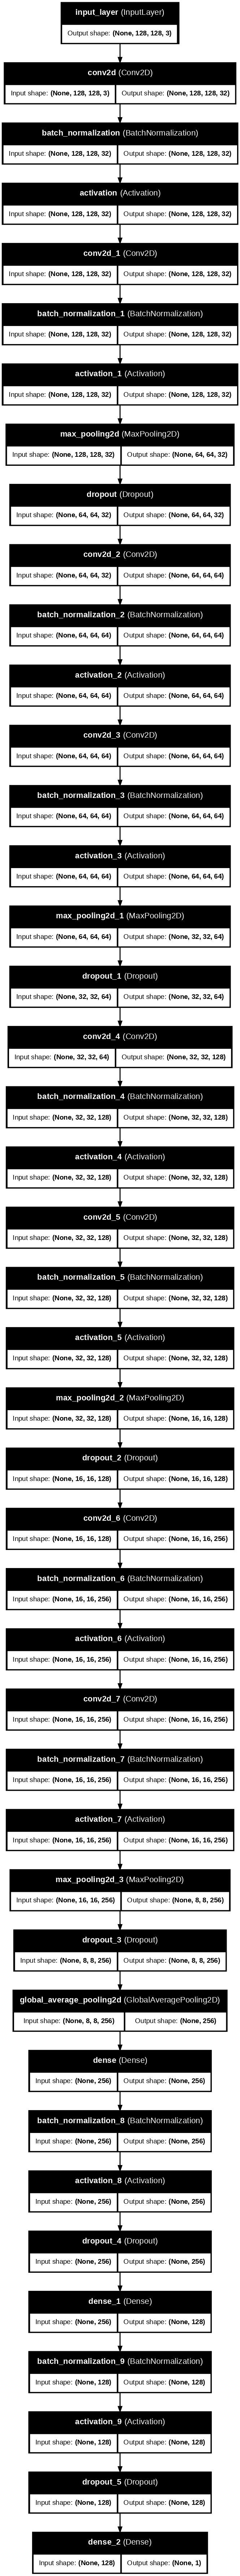

In [11]:
tf.keras.utils.plot_model(model, to_file='model_architecture.png',
                          show_shapes=True, show_layer_names=True, dpi=100)
from IPython.display import Image as IPImage
IPImage('model_architecture.png')

## 7. Modelin Derlenmesi ve Eğitimi

In [12]:
LEARNING_RATE = 1e-3
EPOCHS = 50

model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE, clipnorm=1.0),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),
    ModelCheckpoint(
        'best_custom_cnn.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

In [13]:
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=callbacks
)

Epoch 1/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 648ms/step - accuracy: 0.7133 - loss: 0.5994
Epoch 1: val_accuracy improved from None to 0.60852, saving model to best_custom_cnn.keras

Epoch 1: finished saving model to best_custom_cnn.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 95s 803ms/step - accuracy: 0.7752 - loss: 0.5222 - val_accuracy: 0.6085 - val_loss: 0.8602 - learning_rate: 0.0010
Epoch 2/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 510ms/step - accuracy: 0.8333 - loss: 0.4081
Epoch 2: val_accuracy improved from 0.60852 to 0.67140, saving model to best_custom_cnn.keras

Epoch 2: finished saving model to best_custom_cnn.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 52s 595ms/step - accuracy: 0.8336 - loss: 0.4078 - val_accuracy: 0.6714 - val_loss: 0.8862 - learning_rate: 0.0010
Epoch 3/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 485ms/step - accuracy: 0.8392 - loss: 0.3914
Epoch 3: val_accuracy improved from 0.67140 to 0.68357, saving model to best_custom_cnn.keras

Epoch 3: finished saving model to best_custom_cnn.keras
88/88 ━━

## 8. Eğitim Sonuçlarının Görselleştirilmesi

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(history.history['loss'], label='Eğitim Kaybı', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Doğrulama Kaybı', linewidth=2)
axes[0].set_title('Eğitim ve Doğrulama Kaybı (Loss)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Kayıp (Loss)')
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['accuracy'], label='Eğitim Doğruluğu', linewidth=2)
axes[1].plot(history.history['val_accuracy'], label='Doğrulama Doğruluğu', linewidth=2)
axes[1].set_title('Eğitim ve Doğrulama Doğruluğu (Accuracy)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Doğruluk (Accuracy)')
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Test Seti Üzerinde Değerlendirme

In [ ]:
model.load_weights('best_custom_cnn.keras')

test_generator.reset()
y_pred_probs = model.predict(test_generator)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()
y_true = test_generator.classes

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

print("=" * 50)
print("TEST SETİ SONUÇLARI (Özel CNN Modeli)")
print("=" * 50)
print(f"Doğruluk (Accuracy):   {accuracy:.4f}  ({accuracy*100:.2f}%)")
print(f"Precision (Kesinlik):  {precision:.4f}  ({precision*100:.2f}%)")
print(f"Recall (Duyarlılık):   {recall:.4f}  ({recall*100:.2f}%)")
print(f"F1-Score:              {f1:.4f}  ({f1*100:.2f}%)")
print("=" * 50)

In [ ]:
print("\nSınıf Bazlı Detaylı Rapor (Classification Report):\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

## 10. Confusion Matrix (Karışıklık Matrisi)

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0.5, linecolor='gray', annot_kws={'size': 16})
plt.title('Confusion Matrix - Özel CNN Modeli', fontsize=14, fontweight='bold')
plt.xlabel('Tahmin Edilen Sınıf', fontsize=12)
plt.ylabel('Gerçek Sınıf', fontsize=12)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(8, 6))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='YlOrRd',
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0.5, linecolor='gray', vmin=0, vmax=1, annot_kws={'size': 16})
plt.title('Normalize Edilmiş Confusion Matrix - Özel CNN Modeli', fontsize=14, fontweight='bold')
plt.xlabel('Tahmin Edilen Sınıf', fontsize=12)
plt.ylabel('Gerçek Sınıf', fontsize=12)
plt.tight_layout()
plt.savefig('confusion_matrix_normalized.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Sınıf Bazlı Performans Görselleştirmesi

In [ ]:
report_dict = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)

class_precision = [report_dict[c]['precision'] for c in class_names]
class_recall = [report_dict[c]['recall'] for c in class_names]
class_f1 = [report_dict[c]['f1-score'] for c in class_names]

x_pos = np.arange(len(class_names))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x_pos - width, class_precision, width, label='Precision', color='#2196F3')
bars2 = ax.bar(x_pos, class_recall, width, label='Recall', color='#4CAF50')
bars3 = ax.bar(x_pos + width, class_f1, width, label='F1-Score', color='#FF9800')

ax.set_xlabel('Sınıf', fontsize=12)
ax.set_ylabel('Skor', fontsize=12)
ax.set_title('Sınıf Bazlı Precision, Recall ve F1-Score', fontsize=14, fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(class_names)
ax.legend(fontsize=11)
ax.set_ylim(0, 1.15)
ax.grid(axis='y', alpha=0.3)

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.2f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('class_performance.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Örnek Tahminlerin Görselleştirilmesi

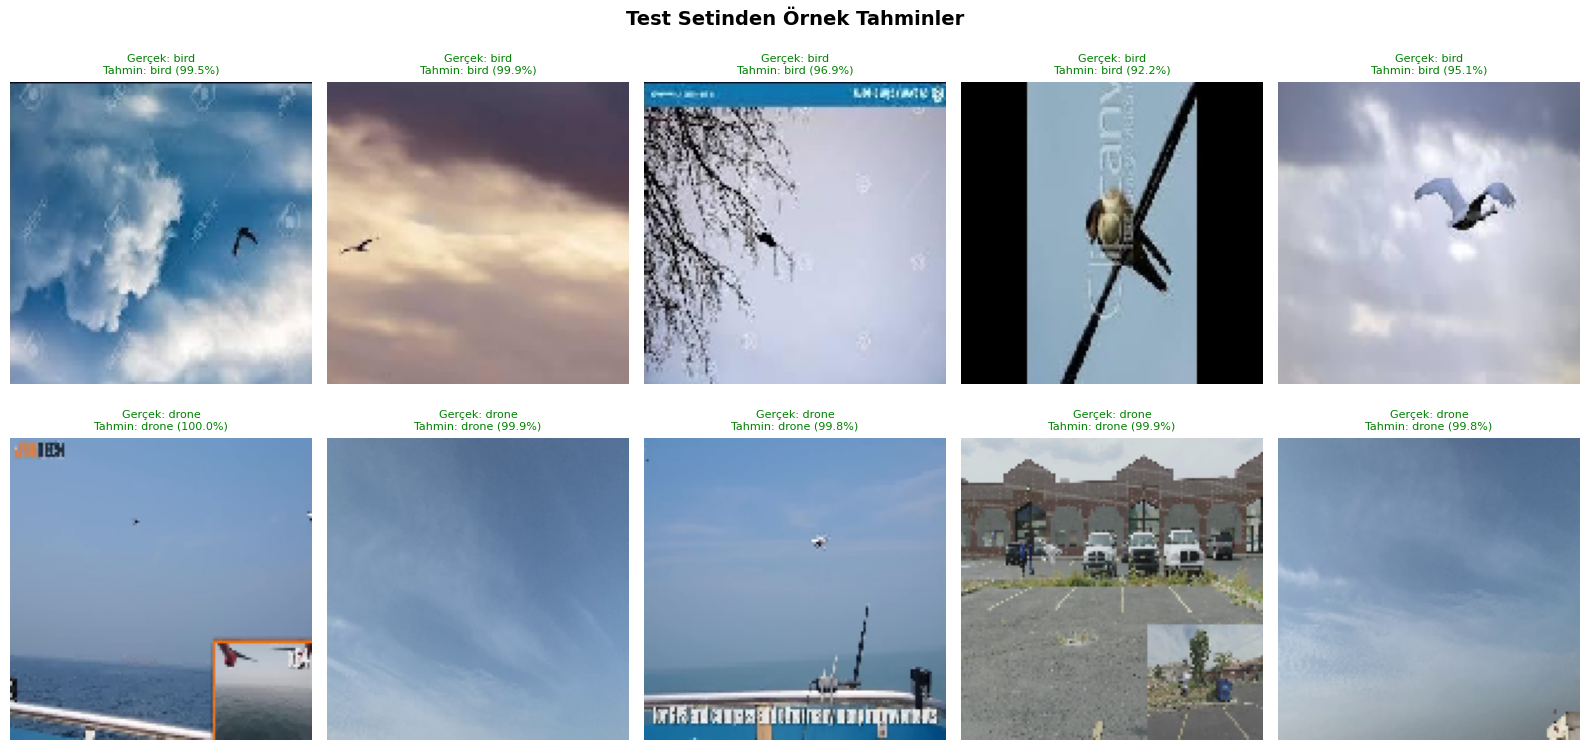

In [ ]:
import random
from tensorflow.keras.preprocessing import image

sample_images_list = []
sample_true_labels = []

for cls in class_names:
    cls_path = os.path.join(TEST_DIR, cls)
    files = os.listdir(cls_path)
    chosen = random.sample(files, min(5, len(files)))
    for f in chosen:
        img = image.load_img(os.path.join(cls_path, f), target_size=(IMG_SIZE, IMG_SIZE))
        img_array = image.img_to_array(img) / 255.0
        sample_images_list.append(img_array)
        sample_true_labels.append(cls)

sample_images_arr = np.array(sample_images_list)
sample_preds = model.predict(sample_images_arr, verbose=0)

plt.figure(figsize=(16, 8))
for i in range(min(10, len(sample_images_arr))):
    plt.subplot(2, 5, i+1)
    plt.imshow(sample_images_arr[i])

    true_label = sample_true_labels[i]
    pred_prob = sample_preds[i][0]
    pred_label = class_names[1] if pred_prob > 0.5 else class_names[0]
    confidence = pred_prob * 100 if pred_prob > 0.5 else (1 - pred_prob) * 100

    color = 'green' if true_label == pred_label else 'red'
    plt.title(f'Gerçek: {true_label}\nTahmin: {pred_label} ({confidence:.1f}%)',
              fontsize=8, color=color)
    plt.axis('off')

plt.suptitle('Test Setinden Örnek Tahminler', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('sample_predictions.png', dpi=150, bbox_inches='tight')
plt.show()

## 13. Model Özeti ve Sonuçlar

In [ ]:
total_params = model.count_params()
trainable_params = sum(tf.keras.backend.count_params(w) for w in model.trainable_weights)
non_trainable_params = total_params - trainable_params

print("=" * 60)
print("ÖZEL CNN MODELİ - GENEL ÖZET")
print("=" * 60)
print(f"Model Adı:               Custom_DroneVsBird_CNN")
print(f"Giriş Boyutu:            {IMG_SIZE}x{IMG_SIZE}x3")
print(f"Sınıf Sayısı:            {num_classes} (Bird, Drone)")
print(f"Toplam Parametre:        {total_params:,}")
print(f"Eğitilebilir Parametre:  {trainable_params:,}")
print(f"Eğitilemeyen Parametre:  {non_trainable_params:,}")
print(f"-" * 60)
print(f"Test Doğruluğu:          {accuracy*100:.2f}%")
print(f"Test Precision:          {precision*100:.2f}%")
print(f"Test Recall:             {recall*100:.2f}%")
print(f"Test F1-Score:           {f1*100:.2f}%")
print(f"Eğitim Epoch Sayısı:     {len(history.history['loss'])}")
print("=" * 60)
print("\nMimari: 4 Konvolüsyon Bloğu (32→64→128→256 filtre)")
print("Her blok: Conv2D→BN→ReLU→Conv2D→BN→ReLU→MaxPool→Dropout")
print("Sınıflandırma: GAP→Dense(256)→Dense(128)→Sigmoid(1)")
print("Optimizasyon: Adam (clipnorm=1.0), LR=0.001")
print("Düzenlileştirme: BatchNorm, Dropout, Data Augmentation")

ÖZEL CNN MODELİ - GENEL ÖZET
Model Adı:               Custom_DroneVsBird_CNN
Giriş Boyutu:            128x128x3
Sınıf Sayısı:            2 (Bird, Drone)
Toplam Parametre:        1,276,449
Eğitilebilir Parametre:  1,273,761
Eğitilemeyen Parametre:  2,688
------------------------------------------------------------
Test Doğruluğu:          95.26%
Test Precision:          95.25%
Test Recall:             95.26%
Test F1-Score:           95.25%
Eğitim Epoch Sayısı:     42

Mimari: 4 Konvolüsyon Bloğu (32→64→128→256 filtre)
Her blok: Conv2D→BN→ReLU→Conv2D→BN→ReLU→MaxPool→Dropout
Sınıflandırma: GAP→Dense(256)→Dense(128)→Sigmoid(1)
Optimizasyon: Adam (clipnorm=1.0), LR=0.001
Düzenlileştirme: BatchNorm, Dropout, Data Augmentation


## 14. Kendi Görsellerinizi Test Edin

Aşağıdan internetten indirdiğiniz veya kendi çektiğiniz drone/kuş görsellerini yükleyerek modeli test edebilirsiniz.

In [ ]:
from google.colab import files

def predict_uploaded_image(model, img_size, class_names):
    uploaded = files.upload()

    for filename in uploaded.keys():
        img = image.load_img(filename, target_size=(img_size, img_size))
        img_array = image.img_to_array(img) / 255.0
        img_array = np.expand_dims(img_array, axis=0)

        prediction = model.predict(img_array, verbose=0)
        pred_prob = prediction[0][0]
        pred_label = class_names[1] if pred_prob > 0.5 else class_names[0]
        confidence = pred_prob * 100 if pred_prob > 0.5 else (1 - pred_prob) * 100

        plt.figure(figsize=(6, 6))
        plt.imshow(image.load_img(filename))
        plt.axis('off')
        plt.title(f'Tahmin: {pred_label} ({confidence:.1f}%)',
                  fontsize=14, fontweight='bold',
                  color='green' if confidence > 80 else 'orange')
        plt.show()

        print(f"\n{'='*40}")
        print(f"Dosya: {filename}")
        print(f"Tahmin: {pred_label}")
        print(f"Güven: {confidence:.1f}%")
        print(f"{'='*40}")
        print(f"\nBird olasılığı: {(1-pred_prob)*100:.1f}%")
        print(f"Drone olasılığı: {pred_prob*100:.1f}%")
        print()

predict_uploaded_image(model, IMG_SIZE, class_names)

Birden fazla görsel test etmek için yukarıdaki hücreyi tekrar çalıştırabilirsiniz.